<a href="https://colab.research.google.com/github/ikabrain/UCS772-CV-NLP-Lab/blob/main/7_Callbacks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =========================
# 1. IMPORT LIBRARIES
# =========================
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [ ]:

# =========================
# 2. LOAD DATA (IMDB)
# =========================
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=vocab_size)

In [ ]:
x_train[0]

In [ ]:


# =========================
# 3. PAD SEQUENCES
# =========================
x_train = keras.preprocessing.sequence.pad_sequences(x_train, maxlen=max_length)
x_test = keras.preprocessing.sequence.pad_sequences(x_test, maxlen=max_length)

In [ ]:
# =========================
# 4. TRAIN-VALIDATION SPLIT
# =========================
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)


In [ ]:

# =========================
# 5. BUILD LSTM MODEL
# =========================
model = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=128, input_length=max_length),

    layers.Bidirectional(layers.LSTM(64, return_sequences=True)),
    layers.Dropout(0.3),

    layers.Bidirectional(layers.LSTM(32)),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')  # binary classification
])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:

# =========================
# 6. COMPILE MODEL
# =========================
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [ ]:

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Creates a folder named checkpoints
This is where your model will be saved

Why needed:

If the folder doesn’t exist → saving model will crash

exist_ok=True → avoids error if folder already exists

If folder does not exist → create it

If folder already exists → do nothing (no error)

In [ ]:
import os

os.makedirs("/content/drive/MyDrive/checkpoints", exist_ok=True)

What is ModelCheckpoint?

It is a Keras callback that:

Automatically saves your model during training

If your training gets interrupted (e.g., system crash, power failure), you can resume from the last saved model checkpoint instead of starting over. This is done using ModelCheckpoint along with reloading the saved model before restarting training



#ModelCheckpoint Callback

The ModelCheckpoint callback automatically saves the best model during training based on a chosen metric, so you don't lose progress if training is interrupted.
'best_model.h5'- Saves the best model's weights in this file.

monitor='val_accuracy' Tracks validation accuracy (val_accuracy).

save_best_only=True Saves only when val_accuracy improves.

mode='max' Saves when val_accuracy increases (maximization).

verbose=1 Prints a message when saving a new best model.

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping


In [ ]:


# =========================
# 7. CALLBACKS
# =========================
checkpoint_cb = ModelCheckpoint(
    "/content/drive/MyDrive/checkpoints/best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

Path where model will be saved

The model is checked after every epoch
If validation accuracy improves, the model is saved

Only the best model so far is kept



# ModelCheckpoint for every epoch

checkpoint_cb = keras.callbacks.ModelCheckpoint(
  
    filepath="checkpoints/model_epoch_{epoch:02d}.keras",

    monitor="val_accuracy",     # optional (still useful for logs)

    save_best_only=False,       # IMPORTANT: save every epoch

    mode="max",

    verbose=1

)

epoch → current epoch number
02d → format as 2 digits

checkpoints/model_epoch_01.keras

checkpoints/model_epoch_02.keras

checkpoints/model_epoch_03.keras
...

In [ ]:
model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=2,
    batch_size=64,
    callbacks=[checkpoint_cb]
)

Epoch 1/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - accuracy: 0.8570 - loss: 0.3502
Epoch 1: val_accuracy improved from None to 0.86860, saving model to /content/drive/MyDrive/checkpoints/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/checkpoints/best_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 212s 677ms/step - accuracy: 0.8661 - loss: 0.3298 - val_accuracy: 0.8686 - val_loss: 0.3182
Epoch 2/2
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 610ms/step - accuracy: 0.9267 - loss: 0.2031
Epoch 2: val_accuracy did not improve from 0.86860
313/313 ━━━━━━━━━━━━━━━━━━━━ 253s 651ms/step - accuracy: 0.9208 - loss: 0.2125 - val_accuracy: 0.8284 - val_loss: 0.3805


In [ ]:
model.summary

| Situation                | What to use             |
| ------------------------ | ----------------------- |
| Normal training          | `save_best_only=True` ✔ |
| Experiment / research    | Save every epoch ✔      |
| Long training / unstable | Save every epoch ✔      |


Advantages

Identify underfitting, optimal point, and overfitting

If training stops (e.g., crash, disconnect), training can resume from last saved model

Useful for studying how the model learns over time

You can choose the best model manually instead of relying only on validation metrics

Combine predictions from multiple epochs to improve accuracy

Disadvantages

Consumes more storage-
Many model files are saved

Slightly slower training-
Saving model each epoch adds overhead


Use save_best_only=True → for normal use (recommended)

Use save_best_only=False → for experimentation, debugging, or recovery

#Early stopping

Phase 1: ✔ Learning

Both training loss ↓

Validation loss ↓

Phase 2:  Best Point

Validation loss reaches minimum

This is the best model

Phase 3:  Overfitting

Training loss ↓

Validation loss ↑

Model starts memorizing instead of generalizing

#stop training when validation loss stops improving

In [ ]:

# 3. Early stopping
early_stop_cb = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

Train → Check val_loss

      ↓

No improvement?

      ↓

Wait 4 epochs (patience)

      ↓

Still no improvement?

      ↓

STOP training + restore best weights

The model will retain the weights from the best-performing epoch (based on the monitored metric, here val_loss).

In [ ]:
model.fit(x_train,y_train,batch_size=64,epochs=10,validation_data=(x_test,y_test),callbacks=[early_stop_cb])

#  Reduce LR when training stagnates
    reduce_lr_callback = ReduceLROnPlateau(
    monitor="val_loss",  # Watch validation loss
    factor=0.1,  # Reduce LR by 10x
    patience=3,  # Wait 3 epochs before reducing LR
    verbose=1,  # Print LR updates
    mode="min",  # Minimize val_loss
    min_lr=1e-6  # Prevent LR from getting too small
 )

In [ ]:


# 2. Reduce learning rate
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=2,
    verbose=1,
    min_lr=1e-6
)


In [ ]:
model.fit(x_train,y_train,epochs=10,verbose=2,batch_size=64,
          validation_data=(x_test,y_test),callbacks=[save_callback,reduce_lr])

In [ ]:

# =========================
# 9. EVALUATE
# =========================
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"\nTest Accuracy: {test_acc:.4f}")

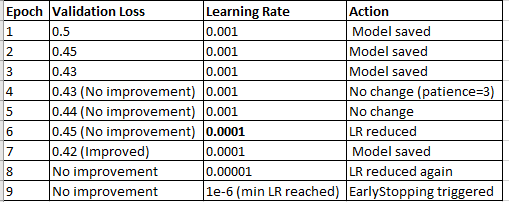